In [1]:
# controles para el sistema operativo
import os

# trabajo con tablas
import pandas as pd

# funciones matematicas
import numpy as np

# visualizacion
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [8]:
# Cargar datos
ad_data = pd.read_csv('../datasets/advertising.xls')

# Vistazo rápido
ad_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


In [7]:
ad_data.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,65.000200,36.009000,55000.000080,180.000100,0.481000,0.50000
std,15.853615,8.785562,13414.634022,43.902339,0.499889,0.50025
min,32.600000,19.000000,13996.500000,104.780000,0.000000,0.00000
25%,51.360000,29.000000,47031.802500,138.830000,0.000000,0.00000
50%,68.215000,35.000000,57012.300000,183.130000,0.000000,0.50000
75%,78.547500,42.000000,65470.635000,218.792500,1.000000,1.00000
max,91.430000,61.000000,79484.800000,269.960000,1.000000,1.00000


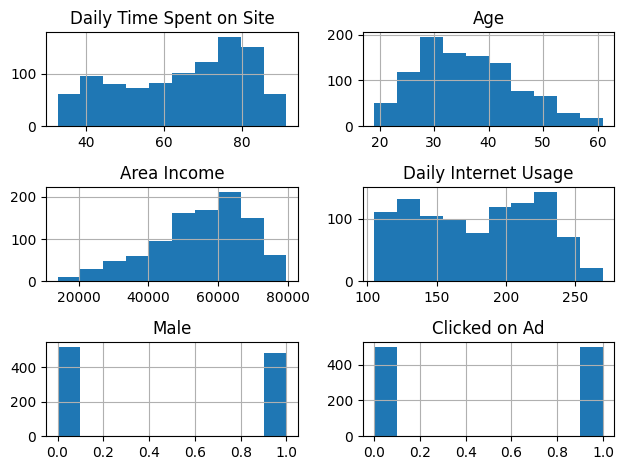

In [5]:
ad_data.hist()
plt.tight_layout()

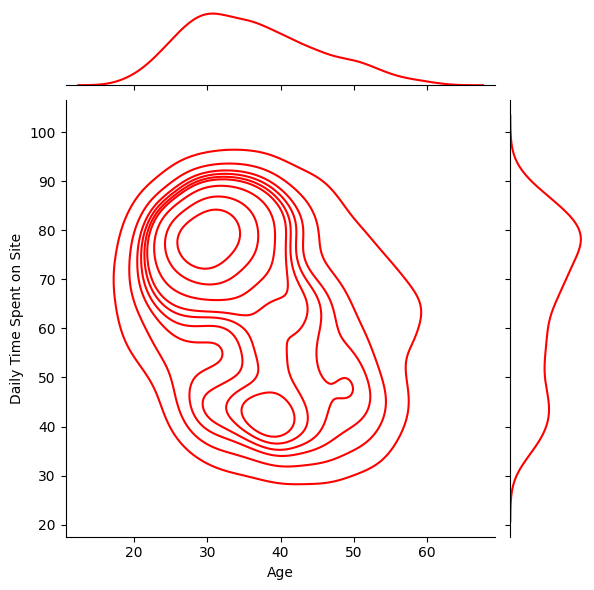

In [9]:
sns.jointplot(x='Age', y='Daily Time Spent on Site', data=ad_data, color='red', kind='kde')

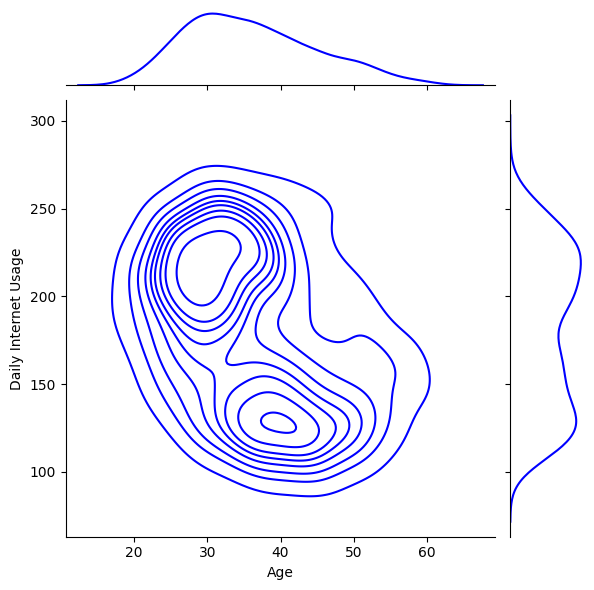

In [10]:
sns.jointplot(x='Age', y='Daily Internet Usage', data=ad_data, color='blue', kind='kde')

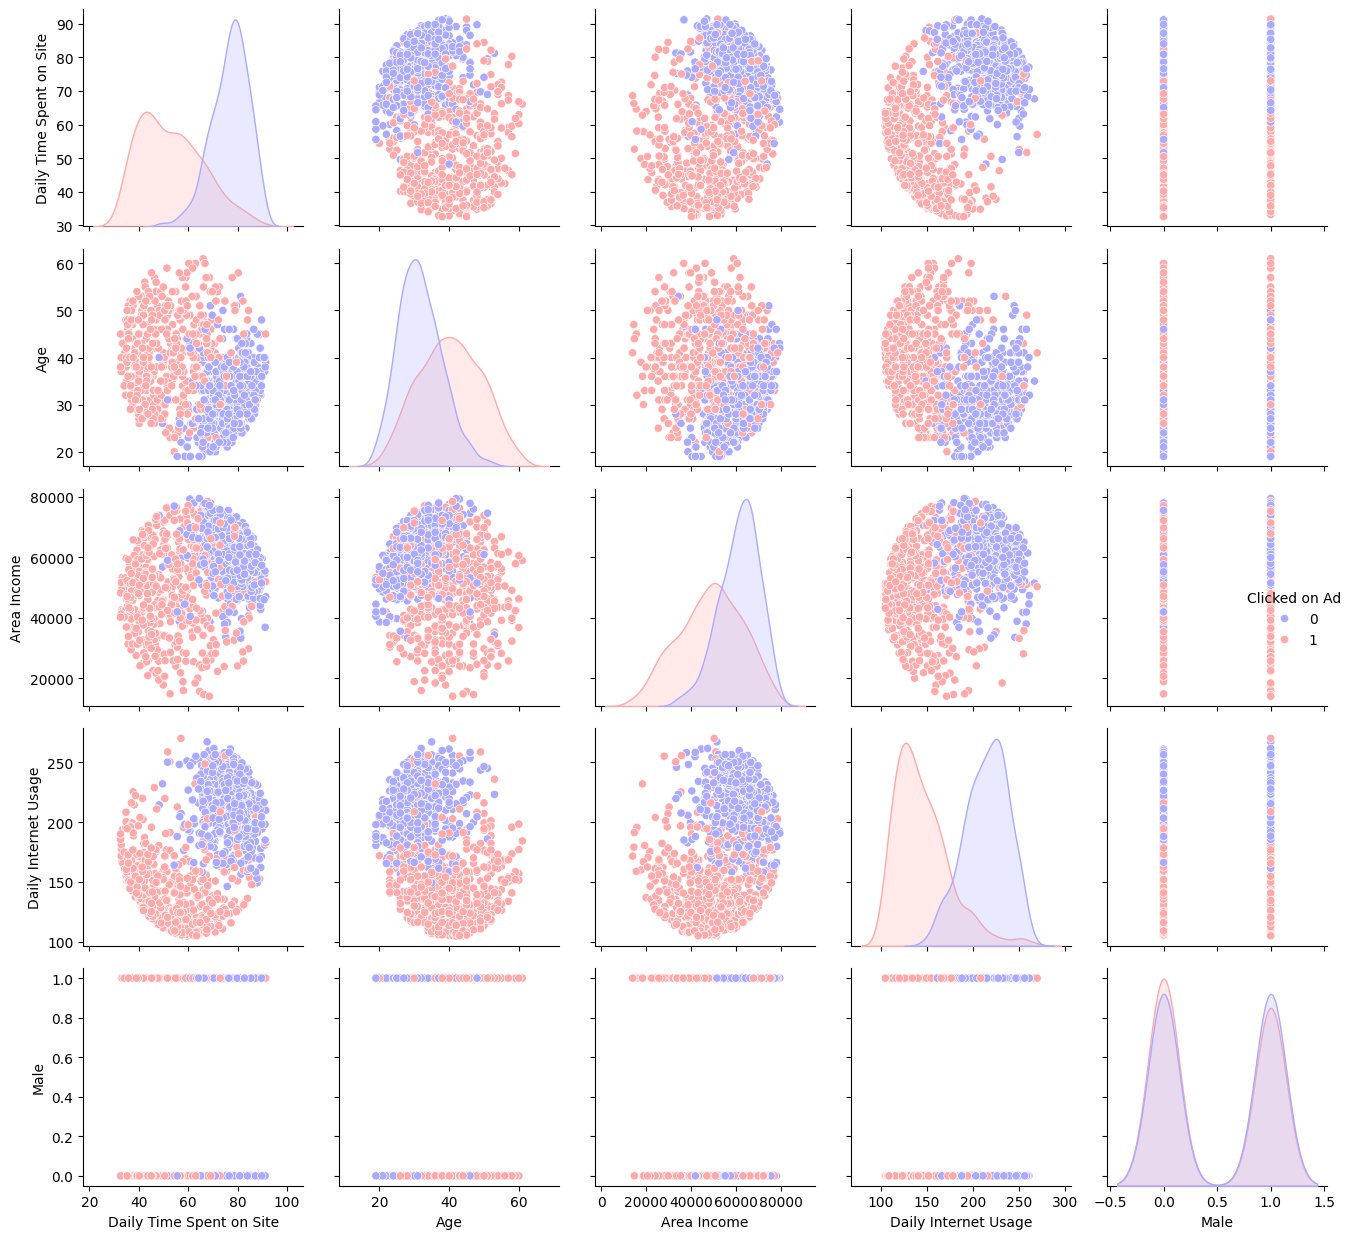

In [12]:
sns.pairplot(ad_data, hue='Clicked on Ad', palette='bwr')
plt.tight_layout()

In [15]:
# 1. Eliminar columnas que no usaremos
#ad_data.drop(['Ad Topic Line', 'City', 'Country', 'Timestamp'], axis=1, inplace=True)

# 2. Separar X (features) e Y (target)
X = ad_data.drop('Clicked on Ad', axis=1)
y = ad_data['Clicked on Ad']

print("Preprocesamiento listo. Columnas X:")
X.head()

Preprocesamiento listo. Columnas X:


,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male
0,68.95,35,61833.90,256.09,0
1,80.23,31,68441.85,193.77,1
2,69.47,26,59785.94,236.50,0
3,74.15,29,54806.18,245.89,1
4,68.37,35,73889.99,225.58,0


In [16]:
print("Preprocesamiento listo. Columnas Y:")
y.head()

Preprocesamiento listo. Columnas Y:


0    0
1    0
2    0
3    0
4    0
Name: Clicked on Ad, dtype: int64

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Escalar
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos escalados y listos para modelar.")

Datos escalados y listos para modelar.


In [18]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# 1. Crear y Entrenar LDA
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_scaled, y_train)
print("Modelo LDA entrenado.")

# 2. Crear y Entrenar QDA
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train_scaled, y_train)
print("Modelo QDA entrenado.")

Modelo LDA entrenado.
Modelo QDA entrenado.


In [19]:
from sklearn.metrics import confusion_matrix, classification_report

# Predecir con LDA
y_pred_lda = lda.predict(X_test_scaled)

print("--- Reporte de Clasificación LDA ---")
print(classification_report(y_test, y_pred_lda))

--- Reporte de Clasificación LDA ---
              precision    recall  f1-score   support

           0       0.90      0.98      0.94        89
           1       0.98      0.91      0.94       111

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.94       200
weighted avg       0.94      0.94      0.94       200



In [20]:
# Predecir con QDA
y_pred_qda = qda.predict(X_test_scaled)

print("--- Reporte de Clasificación QDA ---")
print(classification_report(y_test, y_pred_qda))

--- Reporte de Clasificación QDA ---
              precision    recall  f1-score   support

           0       0.94      0.91      0.93        89
           1       0.93      0.95      0.94       111

    accuracy                           0.94       200
   macro avg       0.94      0.93      0.93       200
weighted avg       0.94      0.94      0.93       200



AUC (LDA): 0.9776
AUC (QDA): 0.9815


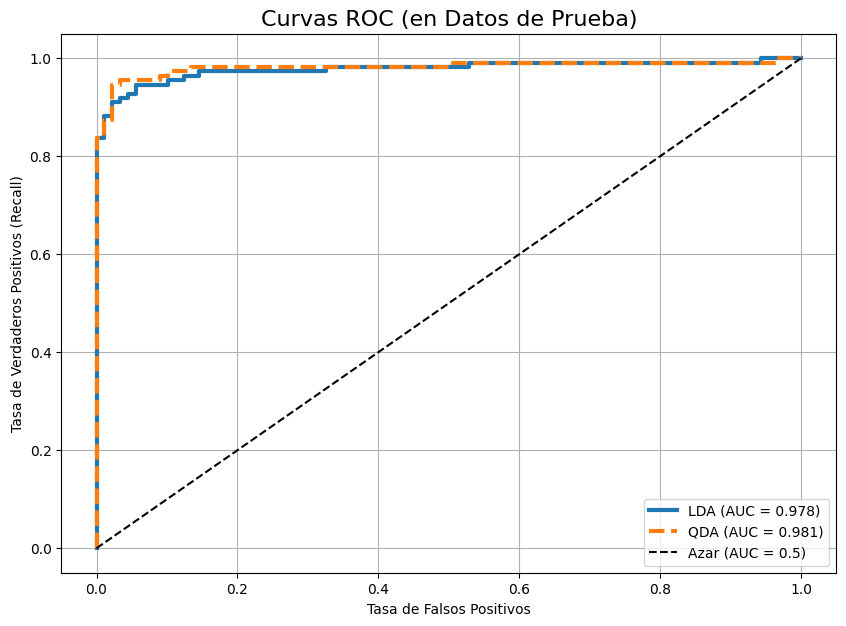

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score


# --- 1. Obtener las probabilidades de la Clase '1' ---
y_prob_lda = lda.predict_proba(X_test_scaled)[:, 1]
y_prob_qda = qda.predict_proba(X_test_scaled)[:, 1]

# --- 2. Calcular los puntajes AUC ---
auc_lda = roc_auc_score(y_test, y_prob_lda)
auc_qda = roc_auc_score(y_test, y_prob_qda)

print(f"AUC (LDA): {auc_lda:.4f}")
print(f"AUC (QDA): {auc_qda:.4f}")

# --- 3. Obtener los datos para las curvas ---
fpr_lda, tpr_lda, _ = roc_curve(y_test, y_prob_lda)
fpr_qda, tpr_qda, _ = roc_curve(y_test, y_prob_qda)

# --- 4. Graficar ---
plt.figure(figsize=(10, 7))
plt.plot(fpr_lda, tpr_lda, label=f'LDA (AUC = {auc_lda:.3f})', linewidth=3)
plt.plot(fpr_qda, tpr_qda, label=f'QDA (AUC = {auc_qda:.3f})', linewidth=3, linestyle='--')
plt.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.5)') # Línea de azar

plt.title('Curvas ROC (en Datos de Prueba)', fontsize=16)
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.legend()
plt.grid()
plt.show()

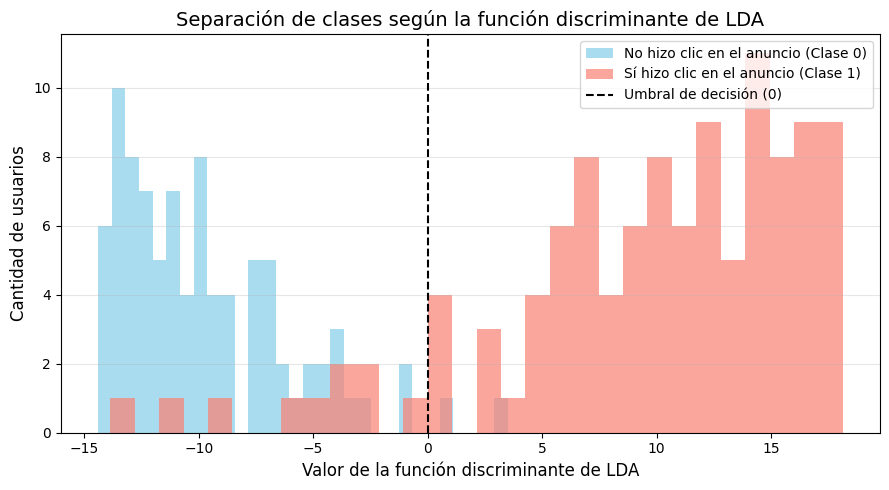

In [22]:
# Obtener los valores de la función discriminante para los datos de prueba
lda_scores = lda.decision_function(X_test_scaled)

# Graficar el histograma de la función discriminante para cada clase
plt.figure(figsize=(9, 5))
plt.hist(lda_scores[y_test == 0], bins=30, alpha=0.7, label='No hizo clic en el anuncio (Clase 0)', color='skyblue')
plt.hist(lda_scores[y_test == 1], bins=30, alpha=0.7, label='Sí hizo clic en el anuncio (Clase 1)', color='salmon')
plt.axvline(0, color='k', linestyle='--', label='Umbral de decisión (0)')
plt.xlabel('Valor de la función discriminante de LDA', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.title('Separación de clases según la función discriminante de LDA', fontsize=14)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

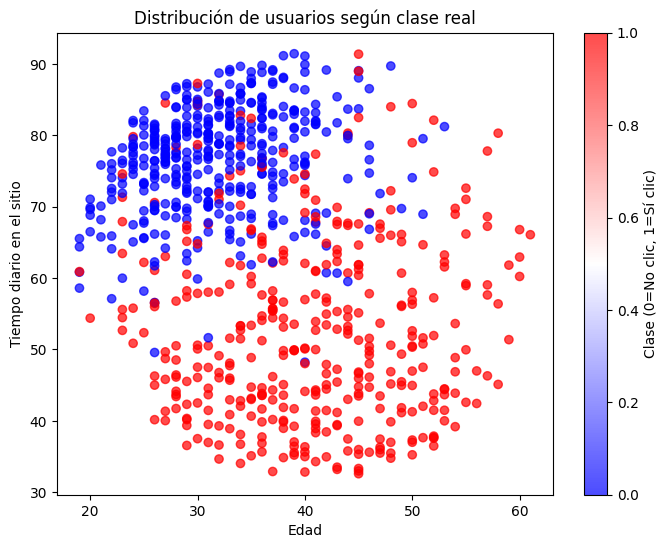

In [23]:
plt.figure(figsize=(8,6))
plt.scatter(X_train['Age'], X_train['Daily Time Spent on Site'], c=y_train, cmap='bwr', alpha=0.7)
plt.xlabel('Edad')
plt.ylabel('Tiempo diario en el sitio')
plt.title('Distribución de usuarios según clase real')
plt.colorbar(label='Clase (0=No clic, 1=Sí clic)')
plt.show()

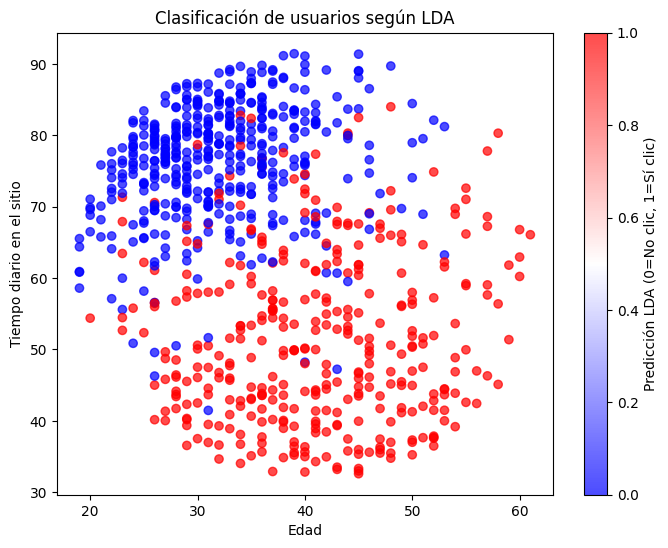

In [24]:
y_pred_train = lda.predict(X_train_scaled)
plt.figure(figsize=(8,6))
plt.scatter(X_train['Age'], X_train['Daily Time Spent on Site'], c=y_pred_train, cmap='bwr', alpha=0.7)
plt.xlabel('Edad')
plt.ylabel('Tiempo diario en el sitio')
plt.title('Clasificación de usuarios según LDA')
plt.colorbar(label='Predicción LDA (0=No clic, 1=Sí clic)')
plt.show()

C:\Users\magal\AppData\Local\Temp\ipykernel_4160\2897871721.py:32: UserWarning: The following kwargs were not used by contour: 'label'
  plt.contour(xx1, xx2, Z, levels=[0], linewidths=3, colors='green', linestyles='--', label='Frontera LDA')


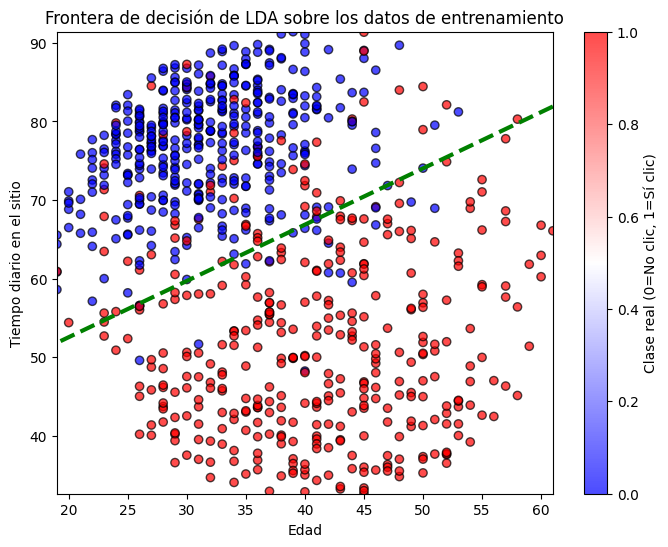

In [25]:
# Selecciona las dos variables principales
x1 = 'Age'
x2 = 'Daily Time Spent on Site'

# Scatterplot de los datos reales
plt.figure(figsize=(8,6))
plt.scatter(X_train[x1], X_train[x2], c=y_train, cmap='bwr', alpha=0.7, edgecolor='k')
plt.xlabel('Edad')
plt.ylabel('Tiempo diario en el sitio')
plt.title('Frontera de decisión de LDA sobre los datos de entrenamiento')
plt.colorbar(label='Clase real (0=No clic, 1=Sí clic)')

# Crear una malla para graficar la frontera
import numpy as np
x1_range = np.linspace(X_train[x1].min(), X_train[x1].max(), 200)
x2_range = np.linspace(X_train[x2].min(), X_train[x2].max(), 200)
xx1, xx2 = np.meshgrid(x1_range, x2_range)
grid = np.c_[xx1.ravel(), xx2.ravel()]

# Para predecir en la malla, necesitamos el resto de variables igual al promedio
X_aux = X_train.mean().to_frame().T.loc[np.repeat(0, grid.shape[0])]
X_aux[x1] = grid[:,0]
X_aux[x2] = grid[:,1]
# Escalar igual que el entrenamiento
grid_scaled = scaler.transform(X_aux)

# Obtener la función discriminante en la malla
Z = lda.decision_function(grid_scaled)
Z = Z.reshape(xx1.shape)

# Dibujar la línea de frontera (donde la función discriminante es 0)
plt.contour(xx1, xx2, Z, levels=[0], linewidths=3, colors='green', linestyles='--', label='Frontera LDA')
plt.show()

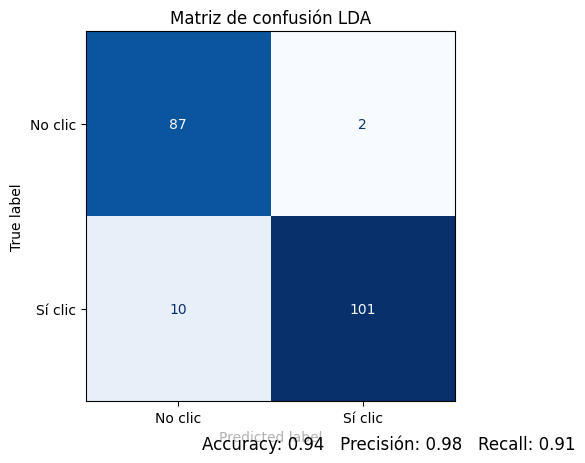

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score

# Mostrar matriz de confusión
ConfusionMatrixDisplay.from_estimator(
    lda, X_test_scaled, y_test, 
    display_labels=['No clic', 'Sí clic'], 
    cmap='Blues', 
    colorbar=False
)
plt.title('Matriz de confusión LDA')

# Calcular métricas
y_pred = lda.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)

# Agregar texto con métricas
plt.figtext(0.99, 0.01, f'Accuracy: {acc:.2f}   Precisión: {prec:.2f}   Recall: {rec:.2f}', 
            horizontalalignment='right', fontsize=12, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.show()

In [28]:
from sklearn.metrics import confusion_matrix, classification_report

# Predecir con LDA
y_pred_lda = lda.predict(X_test_scaled)

print("--- Reporte de Clasificación LDA ---")
print(classification_report(y_test, y_pred_lda))

--- Reporte de Clasificación LDA ---
              precision    recall  f1-score   support

           0       0.90      0.98      0.94        89
           1       0.98      0.91      0.94       111

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.94       200
weighted avg       0.94      0.94      0.94       200



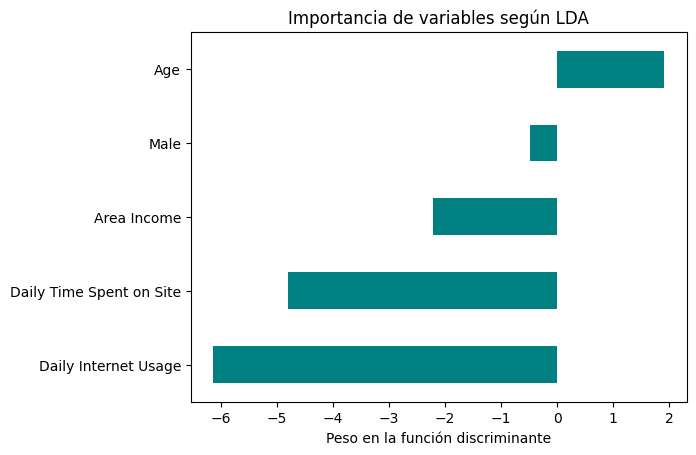

In [29]:
coef = pd.Series(lda.coef_[0], index=X.columns)
coef.sort_values().plot(kind='barh', color='teal')
plt.title('Importancia de variables según LDA')
plt.xlabel('Peso en la función discriminante')
plt.show()

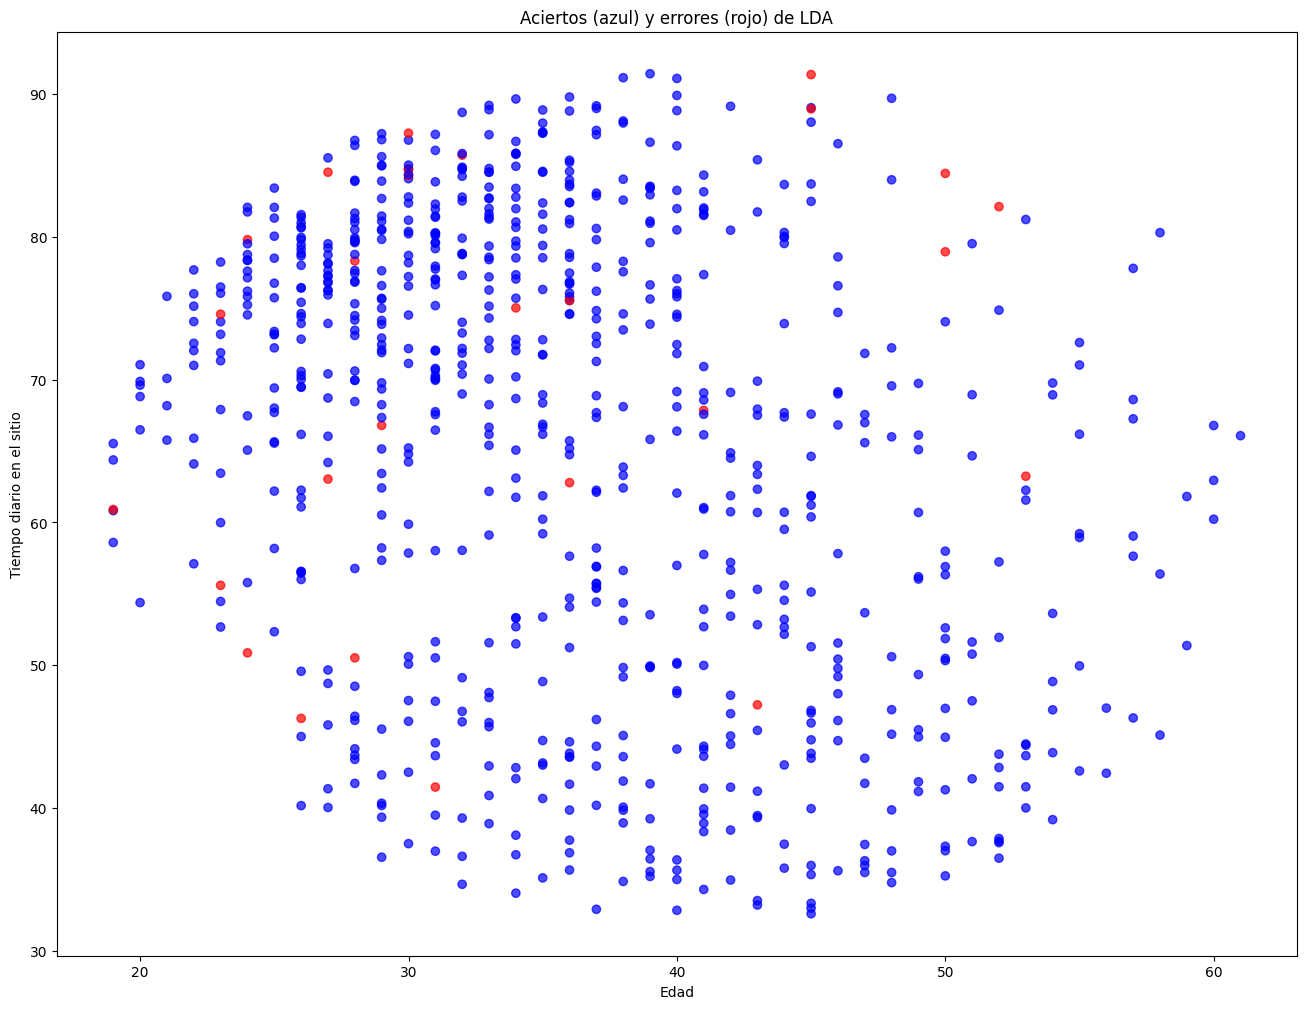

In [31]:
y_pred = lda.predict(X_train_scaled)
acierto = (y_pred == y_train)
plt.figure(figsize=(16,12))
# Usar ['red', 'blue'] para que azul sea acierto y rojo error
plt.scatter(
    X_train['Age'], X_train['Daily Time Spent on Site'],
    c=acierto.map({True: 'blue', False: 'red'}),
    alpha=0.7
)
plt.xlabel('Edad')
plt.ylabel('Tiempo diario en el sitio')
plt.title('Aciertos (azul) y errores (rojo) de LDA')
plt.show()